**integrantes:** Angie Vanessa Gonzalez Farfan, Maria Jose Sandoval Ricaurte, Maria Jose Almanza Caviedes, Angel Santiago Toribio Godoy
# Arboles de regresión / clasificación 
## Explicación y teoria

* Los árboles son modelos de caja blanca: cada predicción se explica como una secuencia de reglas, a diferencia de modelos "caja negra".
* Útiles donde hay que justificar una decisión: créditos, diagnósticos médicos, decisiones judiciales asistidas.
* Capturan relaciones no lineales e interacciones entre variables automáticamente, sin que se especifique.
* Un mismo algoritmo (CART) sirve para Clasificación y Regresión.


### Estructura del árbol
* Nodo raíz: todos los datos, antes de dividir.
* Nodos internos: preguntas binarias sobre una variable ($X_j \leq t$?).
* Ramas: resultado de la pregunta — siempre 2 por nodo (división binaria).
* Nodos hoja: predicción final (clase mayoritaria / media de $y$).
* Proceso: división binaria recursiva — se repite en cada hijo hasta un criterio de parada.


In [2]:
from IPython.display import Image, display

display(Image(filename='concepto.png', width=936))

FileNotFoundError: [Errno 2] No such file or directory: 'concepto.png'

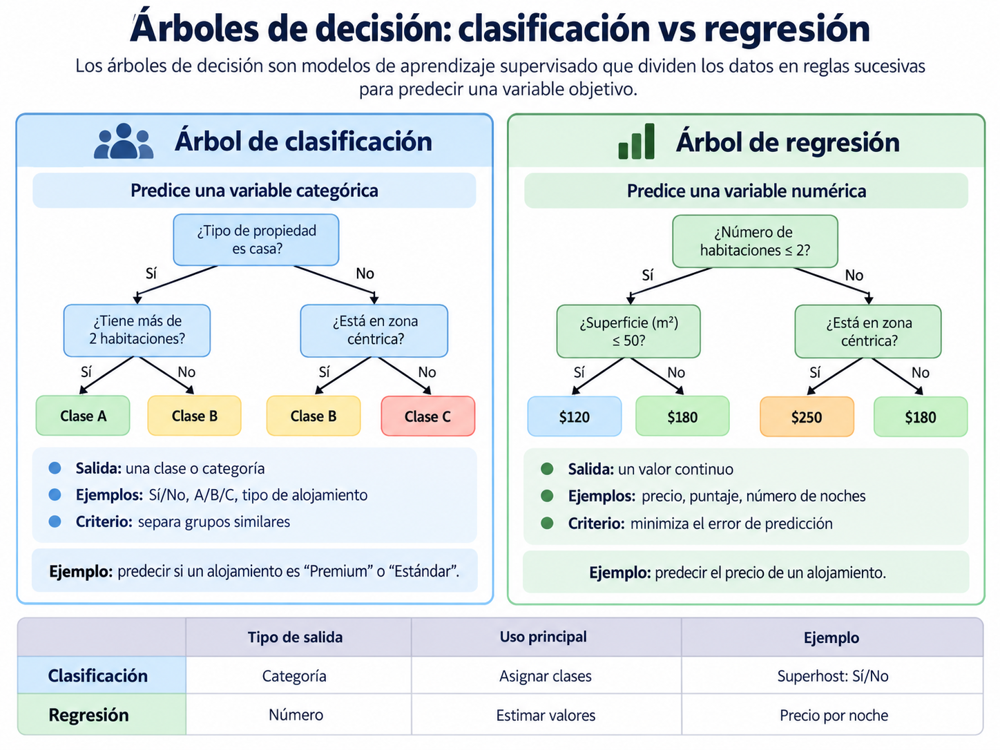

In [ ]:
from IPython.display import Image, display

display(Image(filename='arboles_decision.png', width=1000))

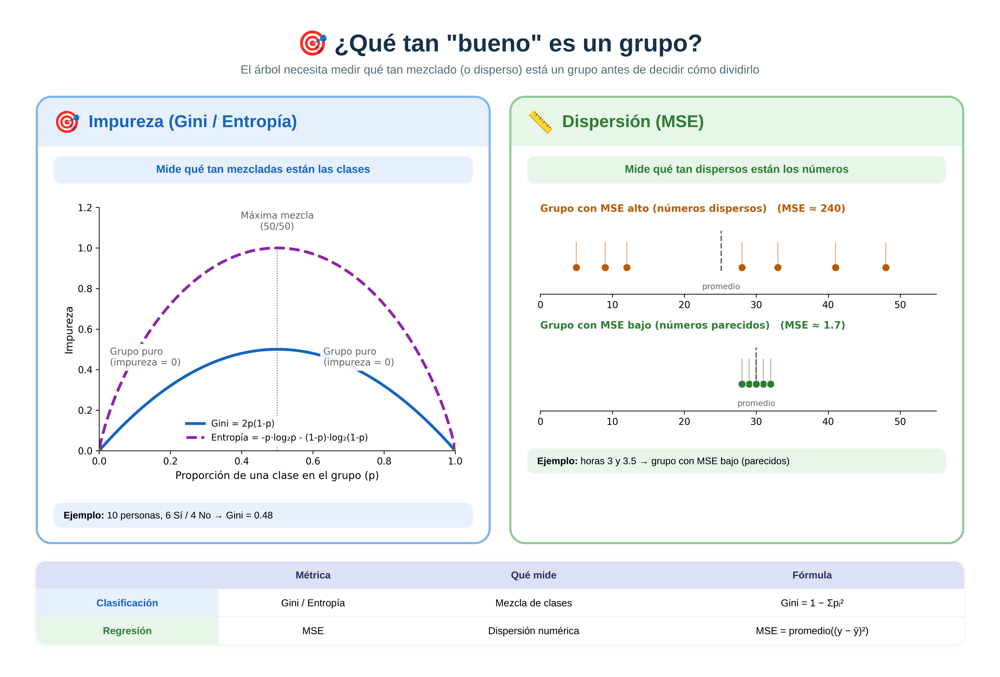

In [ ]:
from IPython.display import Image, display

display(Image(filename='GINI-MSE.png'))

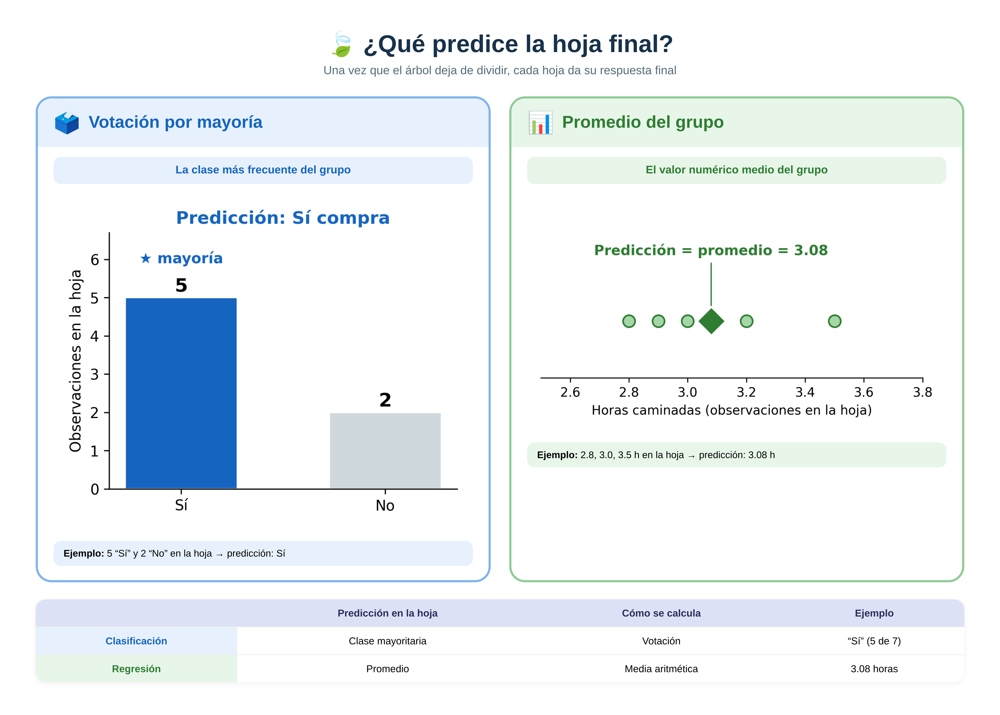

In [ ]:
from IPython.display import Image, display

display(Image(filename='Prediccion.png', width=1000))

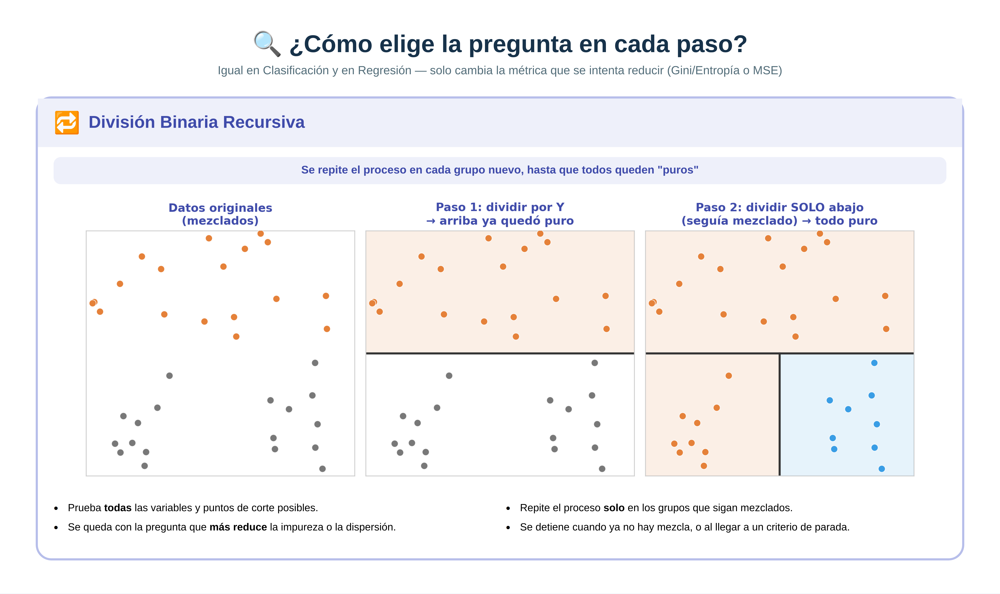

In [ ]:
from IPython.display import Image, display

display(Image(filename='DivisionBinaria.png', width=1000))

##### El algoritmo es greedy: elige la mejor división local en cada paso, sin ver el árbol completo, por eso es rápido pero propenso a sobreajustar.

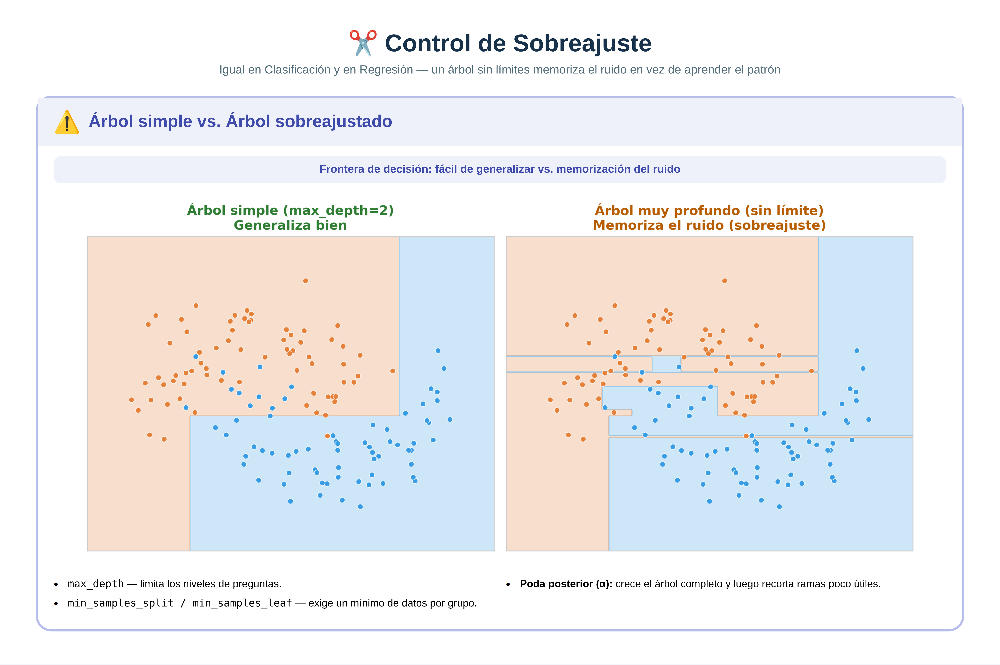

In [ ]:
from IPython.display import Image, display

display(Image(filename='Overfit.png'))

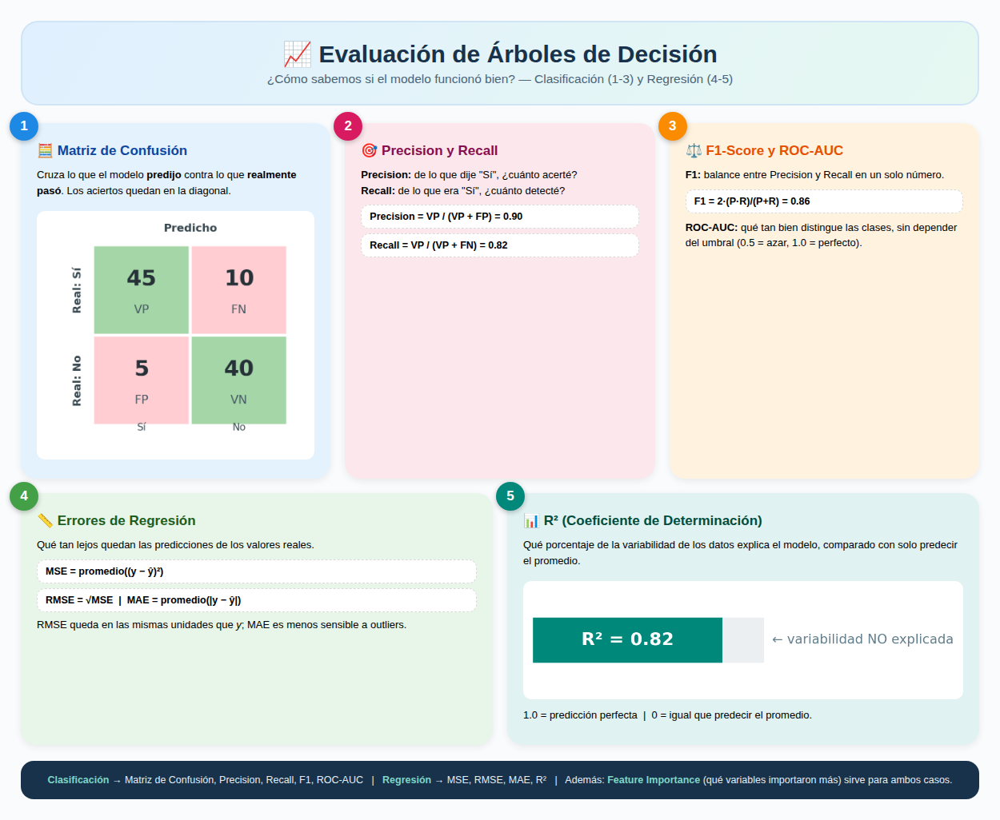

In [ ]:
from IPython.display import Image, display

display(Image(filename='Evaluacion.png', width=1000))

## Ejemplo practico de airbnb
### Limpieza de datos


In [6]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, SVG

from sklearn.model_selection import (train_test_split, validation_curve,
                                     GridSearchCV, KFold, StratifiedKFold)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay)

pd.set_option('display.max_columns', None)

df = pd.read_csv('listings.csv')
df.head()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_name,host_since,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,18674,https://www.airbnb.com/rooms/18674,20250612050654,2025-06-21,city scrape,Huge flat for 8 people close to Sagrada Familia,"110m2 apartment to rent in Barcelona. Located in the Eixample district, near the Sagrada Familia. It has a small balcony where you can see the temple of Gaudi. Capacity for 8 people. <br /><br />Licence number: HUTB-002062","Apartment in Barcelona located in the heart of Eixample district, within only 150 m form the great Sagrada Familia and really near of Gaudí Avenue and the famous Sant Pau Hospital . <br />All kind of services in surroundings (shops, supermarkets, restaurants, bars).",https://a0.muscache.com/pictures/13031453/413cdbfc_original.jpg,71615,https://www.airbnb.com/users/show/71615,Mireia Maria,2010-01-19,"Barcelona, Spain","We are Mireia (47) & Maria (49), two multilingual entrepreneurs loving Barcelona and having big experience in the touristic market.\nAna and Beka from reservation department will attend you\nand feel youself like at home. The location of our flats perfectly suites for travelling and sightseeing.\n\nWe are looking forward to sincerely host you in our apartments.",within an hour,96%,91%,f,https://a0.muscache.com/im/pictures/user/User/original/13242c7b-4fc1-415f-a5d7-6474d869a343.jpeg?aki_policy=profile_small,https://a0.muscache.com/im/pictures/user/User/original/13242c7b-4fc1-415f-a5d7-6474d869a343.jpeg?aki_policy=profile_x_medium,la Sagrada Família,44.0,46.0,"['email', 'phone']",t,t,"Barcelona, CT, Spain",la Sagrada Família,Eixample,41.405560,2.17262,Entire rental unit,Entire home/apt,8,2.0,2 baths,3.0,6.0,"[""30 inch TV"", ""AC - split type ductless system"", ""Hot water"", ""Wifi"", ""Shampoo"", ""Hangers"", ""Hair dryer"", ""Kitchen"", ""Pack \u2019n play/Travel crib"", ""City skyline view"", ""Elevator"", ""Crib"", ""Host greets you"", ""Iron"", ""Free washer \u2013 In unit"", ""Private patio or balcony"", ""Pets allowed"", ""Coffee maker"", ""Dishes and silverware"", ""Refrigerator"", ""Heating"", ""Essentials""]",$232.00,1,1125,1.0,5.0,999.0,999.0,2.2,999.0,NaN,t,11,32,53,65,2025-06-21,48,6,2,65,5,36,8352.0,2013-05-27,2025-06-11,4.30,4.36,4.53,4.62,4.60,4.81,4.28,HUTB-002062,t,28,28,0,0,0.33
1,23197,https://www.airbnb.com/rooms/23197,20250612050654,2025-06-23,city scrape,"Forum CCIB DeLuxe, Spacious, Large Balcony, relax","Beautiful and Spacious Apartment with Large Terrace – Just 5 Minutes from CCIB, 10 Minutes to the Beach and Marina (Port Fòrum).<br /><br />Enjoy the perfect balance of business and leisure in this modern, family-friendly apartment. <br /><br />Relax on th

In [7]:
filas, columnas = df.shape
print(f"{filas} filas, {columnas} columnas")

18927 filas, 79 columnas


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 18927 entries, 0 to 18926
Data columns (total 79 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            18927 non-null  int64  
 1   listing_url                                   18927 non-null  str    
 2   scrape_id                                     18927 non-null  int64  
 3   last_scraped                                  18927 non-null  str    
 4   source                                        18927 non-null  str    
 5   name                                          18927 non-null  str    
 6   description                                   18189 non-null  str    
 7   neighborhood_overview                         9154 non-null   str    
 8   picture_url                                   18927 non-null  str    
 9   host_id                                       18927 non-null  int64  
 1

In [9]:
df.dtypes

id                                                int64
listing_url                                         str
scrape_id                                         int64
last_scraped                                        str
source                                              str
                                                 ...   
calculated_host_listings_count                    int64
calculated_host_listings_count_entire_homes       int64
calculated_host_listings_count_private_rooms      int64
calculated_host_listings_count_shared_rooms       int64
reviews_per_month                               float64
Length: 79, dtype: object

In [10]:
#Pasar a datatime las columnas de fecha
columnas_fecha = ['host_since', 'first_review', 'last_review', 'last_scraped', 'calendar_last_scraped']
for columna in columnas_fecha:
    df[columna] = pd.to_datetime(df[columna], errors='coerce')

#Convertir porcentajes a numeros
df['host_response_rate'] = df['host_response_rate'].str.replace('%', '', regex=False).astype(float)
df['host_acceptance_rate'] = df['host_acceptance_rate'].str.replace('%', '', regex=False).astype(float)

#Convertir a numerico las columnas de precio
df['price'] = df['price'].str.replace('$', '', regex=False)
df['price'] = df['price'].str.replace(',', '', regex=False)
df['price'] = pd.to_numeric(df['price'])

In [11]:
df.dtypes

id                                                       int64
listing_url                                                str
scrape_id                                                int64
last_scraped                                    datetime64[us]
source                                                     str
                                                     ...      
calculated_host_listings_count                           int64
calculated_host_listings_count_entire_homes              int64
calculated_host_listings_count_private_rooms             int64
calculated_host_listings_count_shared_rooms              int64
reviews_per_month                                      float64
Length: 79, dtype: object

In [12]:
# Revisión de missing values
missing_values = df.isnull().sum()
missing_values[missing_values > 0].sort_values(ascending=False)

calendar_updated               18927
host_neighbourhood              9776
neighborhood_overview           9773
neighbourhood                   9773
host_about                      6775
license                         6329
review_scores_checkin           5002
review_scores_accuracy          5001
review_scores_location          5001
review_scores_value             5001
review_scores_cleanliness       5000
review_scores_communication     4999
last_review                     4998
first_review                    4998
reviews_per_month               4998
review_scores_rating            4998
host_location                   4376
beds                            4053
estimated_revenue_l365d         4014
price                           4014
bathrooms                       3985
host_response_rate              2890
host_response_time              2890
host_acceptance_rate            2744
bedrooms                        2057
has_availability                1089
description                      738
h

In [13]:
# Porcentaje de missing values
porcentaje_missing = (df.isnull().sum() / len(df)) * 100
porcentaje_missing[porcentaje_missing > 0].sort_values(ascending=False)

calendar_updated               100.000000
host_neighbourhood              51.651080
neighborhood_overview           51.635230
neighbourhood                   51.635230
host_about                      35.795425
license                         33.439002
review_scores_checkin           26.427854
review_scores_accuracy          26.422571
review_scores_location          26.422571
review_scores_value             26.422571
review_scores_cleanliness       26.417287
review_scores_communication     26.412004
last_review                     26.406721
first_review                    26.406721
reviews_per_month               26.406721
review_scores_rating            26.406721
host_location                   23.120410
beds                            21.413853
estimated_revenue_l365d         21.207798
price                           21.207798
bathrooms                       21.054578
host_response_rate              15.269192
host_response_time              15.269192
host_acceptance_rate            14

In [14]:
# Tratar los missing values
df = df.drop(columns=['calendar_updated']) 

# imputar los missing values de las columnas numéricas con la mediana
df['bedrooms'] = df['bedrooms'].fillna(df.groupby('accommodates')['bedrooms'].transform('median'))
df['beds'] = df['beds'].fillna(df.groupby('accommodates')['beds'].transform('median'))
df['bathrooms'] = df['bathrooms'].fillna(df.groupby('accommodates')['bathrooms'].transform('median'))

In [15]:
# Verificar la cantidad de valores nulos por columna
df.isnull().sum().sort_values(ascending=False)

host_neighbourhood                              9776
neighborhood_overview                           9773
neighbourhood                                   9773
host_about                                      6775
license                                         6329
                                                ... 
instant_bookable                                   0
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
Length: 78, dtype: int64

In [16]:
df.describe()

,id,scrape_id,last_scraped,host_id,host_since,host_response_rate,host_acceptance_rate,host_listings_count,host_total_listings_count,latitude,longitude,accommodates,bathrooms,bedrooms,beds,price,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
count,1.892700e+04,1.892700e+04,18927,1.892700e+04,18924,16037.000000,16183.00000,18924.000000,18924.000000,18927.000000,18927.000000,18927.000000,18927.000000,18927.000000,18927.000000,14913.000000,18927.000000,18927.000000,18923.000000,18923.000000,1.892300e+04,1.892300e+04,18927.000000,1.892700e+04,18927.000000,18927.000000,18927.000000,18927.000000,18927,18927.000000,18927.000000,18927.000000,18927.000000,18927.000000,18927.000000,1.491300e+04,13929,13929,13929.000000,13926.000000,13927.000000,13925.000000,13928.000000,13926.000000,13926.000000,18927.000000,18927.000000,18927.000000,18927.000000,13929.000000
mean,5.644774e+17,2.025061e+13,2025-06-22 19:25:06.990014,2.007217e+08,2017-07-26 09:59:00.646797,92.739353,84.27189,79.357166,101.944673,41.392254,2.166862,3.386538,1.355220,1.774819,2.319015,214.380071,16.428700,513.885930,15.432384,24.501665,2.275181e+05,2.275822e+05,20.087299,2.274984e+05,9.282665,23.305490,40.164950,189.396629,2025-06-22 19:25:06.990014,51.420880,11.485497,1.010197,102.111692,10.613991,81.826808,1.908160e+04,2021-03-10 07:01:10.557829,2024-06-29 01:14:01.266422,4.606036,4.654929,4.621006,4.722626,4.720793,4.752836,4.464138,58.118402,40.914883,17.085698,0.079093,1.454379
min,1.867400e+04,2.025061e+13,2025-06-21 00:00:00,3.073000e+03,2008-09-19 00:00:00,0.000000,0.00000,1.000000,1.000000,41.335310,2.085593,1.000000,0.000000,0.000000,0.000000,9.000000,1.000000,1.000000,1.000000,1.000000,1.000000e+00,1.000000e+00,1.000000,1.000000e+00,0.000000,0.000000,0.000000,0.000000,2025-06-21 00:00:00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,2010-07-10 00:00:00,2011-06-23 00:00:00,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.010000
25%,2.842925e+07,2.025061e+13,2025-06-22 00:00:00,1.142567e+07,2014-01-20 00:00:00,93.000000,78.00000,2.000000,3.000000,41.381170,2.156303,2.000000,1.000000,1.000000,1.000000,74.000000,1.000000,330.000000,1.000000,3.000000,2.680000e+02,3.300000e+02,2.000000,3.300000e+02,0.000000,1.000000,7.000000,75.000000,2025-06-22 00:00:00,0.000000,0.000000,0.000000,38.000000,0.000000,0.000000,0.000000e+00,2018-07-02 00:00:00,2024-09-16 00:00:00,4.500000,4.560000,4.500000,4.670000,4.670000,4.680000,4.330000,2.000000,0.000000,0.000000,0.000000,0.190000
50%,6.396171e+17,2.025061e+13,2025-06-23 00:00:00,1.329791e+08,2017-06-05 12:00:00,100.000000,98.00000,9.000000,12.000000,41.390120,2.167680,3.000000,1.000000,1.000000,2.000000,143.000000,3.000000,365.000000,3.000000,6.000000,3.650000e+02,3.650000e+02,4.400000,3.650000e+02,5.000000,20.000000,40.000000,204.000000,2025-06-23 00:00:00,6.000000,1.000000,0.000000,118.000000,1.000000,30.000000,7.395000e+03,2022-05-12 00:00:00,2025-05-18 00:00:00,4.720000,4.780000,4.750000,4.860000,4.860000,4.850000,4.580000,7.000000,3.000000,0.000000,0.000000,0.750000
75%,1.112177e+18,2.025061e+13,2025-06-23 00:00:00,3.579465e+08,2020-07-23 00:00:00,100.000000,100.00000,47.000000,83.000000,41.401610,2.177699,4.000000,2.000000,2.000000,3.000000

In [17]:
df.duplicated().sum()

np.int64(0)

In [18]:
df.nunique()

id                                              18927
listing_url                                     18927
scrape_id                                           1
last_scraped                                        6
source                                              2
                                                ...  
calculated_host_listings_count                     72
calculated_host_listings_count_entire_homes        62
calculated_host_listings_count_private_rooms       33
calculated_host_listings_count_shared_rooms         7
reviews_per_month                                 831
Length: 78, dtype: int64

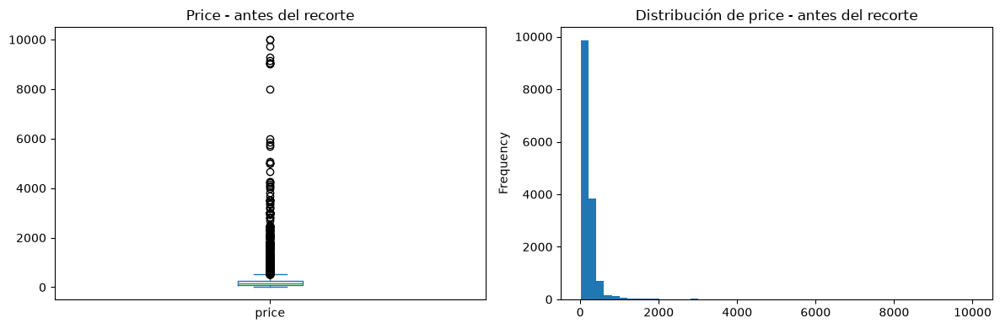

Percentil 99 de price: 1382.00
Nuevo máximo de price tras el recorte: 1382.00


In [19]:
# Tratamineto de outliers 
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df['price'].dropna().plot(kind='box', ax=axes[0])
axes[0].set_title('Price - antes del recorte')
df['price'].dropna().plot(kind='hist', bins=50, ax=axes[1])
axes[1].set_title('Distribución de price - antes del recorte')
plt.tight_layout()
plt.show()

p99 = df['price'].quantile(0.99)
print(f"Percentil 99 de price: {p99:.2f}")

df['price'] = df['price'].clip(upper=p99)

print(f"Nuevo máximo de price tras el recorte: {df['price'].max():.2f}")

In [20]:
columnas_booleanas = [
    'host_is_superhost',
    'host_has_profile_pic',
    'host_identity_verified',
    'instant_bookable',
    'has_availability'
]

for columna in columnas_booleanas:
    df[columna] = df[columna].map({'t': 1, 'f': 0})

In [21]:
columnas_eliminar = [
    'listing_url',
    'picture_url',
    'host_url',
    'host_thumbnail_url',
    'host_picture_url'
]

df = df.drop(columns=columnas_eliminar)

In [22]:
cols_regresion = ['price', 'accommodates', 'bedrooms', 'bathrooms', 'beds',
                   'room_type', 'neighbourhood_group_cleansed',
                   'minimum_nights', 'availability_365', 'instant_bookable']

df_regresion = df[cols_regresion].dropna(subset=['price']).copy()

print(f"df_regresion: {df_regresion.shape[0]} filas, {df_regresion.shape[1]} columnas")
df_regresion.isnull().sum()

df_regresion: 14913 filas, 10 columnas


price                           0
accommodates                    0
bedrooms                        0
bathrooms                       0
beds                            0
room_type                       0
neighbourhood_group_cleansed    0
minimum_nights                  0
availability_365                0
instant_bookable                0
dtype: int64

In [23]:
df_regresion = pd.get_dummies(
    df_regresion,
    columns=['room_type', 'neighbourhood_group_cleansed'],
    drop_first=True
)

df_regresion.head()

,price,accommodates,bedrooms,bathrooms,beds,minimum_nights,availability_365,instant_bookable,room_type_Hotel room,room_type_Private room,room_type_Shared room,neighbourhood_group_cleansed_Eixample,neighbourhood_group_cleansed_Gràcia,neighbourhood_group_cleansed_Horta-Guinardó,neighbourhood_group_cleansed_Les Corts,neighbourhood_group_cleansed_Nou Barris,neighbourhood_group_cleansed_Sant Andreu,neighbourhood_group_cleansed_Sant Martí,neighbourhood_group_cleansed_Sants-Montjuïc,neighbourhood_group_cleansed_Sarrià-Sant Gervasi
0,232.0,8,3.0,2.0,6.0,1,65,1,False,False,False,True,False,False,False,False,False,False,False,False
1,382.0,5,3.0,2.0,4.0,3,174,0,False,False,False,False,False,False,False,False,False,True,False,False
2,186.0,6,2.0,1.5,3.0,1,39,0,False,False,False,False,True,False,False,False,False,False,False,False
3,131.0,2,1.0,1.0,1.0,31,333,0,False,False,False,False,False,False,False,False,False,False,False,False
4,285.0,3,1.0,1.0,3.0,2,365,0,False,False,False,False,False,False,False,False,False,False,False,False


In [24]:
cols_clasificacion = ['host_is_superhost', 'host_response_rate', 'host_acceptance_rate',
                       'number_of_reviews', 'review_scores_rating', 'reviews_per_month']

df_clasificacion = df[cols_clasificacion].dropna(subset=['host_is_superhost']).copy()

print(f"df_clasificacion: {df_clasificacion.shape[0]} filas, {df_clasificacion.shape[1]} columnas")
df_clasificacion.isnull().sum()

df_clasificacion: 18360 filas, 6 columnas


host_is_superhost          0
host_response_rate      2873
host_acceptance_rate    2717
number_of_reviews          0
review_scores_rating    4815
reviews_per_month       4815
dtype: int64

In [25]:
df_clasificacion['sin_reviews'] = df_clasificacion['review_scores_rating'].isnull().astype(int)

for col in ['host_response_rate', 'host_acceptance_rate']:
    df_clasificacion[col] = df_clasificacion[col].fillna(df_clasificacion[col].median())

df_clasificacion['review_scores_rating'] = df_clasificacion['review_scores_rating'].fillna(df_clasificacion['review_scores_rating'].median())

df_clasificacion['reviews_per_month'] = df_clasificacion['reviews_per_month'].fillna(0)
df_clasificacion.isnull().sum()

host_is_superhost       0
host_response_rate      0
host_acceptance_rate    0
number_of_reviews       0
review_scores_rating    0
reviews_per_month       0
sin_reviews             0
dtype: int64

In [26]:
print(df_clasificacion['host_is_superhost'].value_counts())
print()
print(df_clasificacion['host_is_superhost'].value_counts(normalize=True).round(3))

host_is_superhost
0.0    14234
1.0     4126
Name: count, dtype: int64

host_is_superhost
0.0    0.775
1.0    0.225
Name: proportion, dtype: float64


### Modelo 1: Arbol de regresión

* **Separar las variables (columnas predictoras y variable a predecir)**

In [27]:
x = df_regresion.drop(columns=['price'])
y = df_regresion['price']

* **Dividir en entrenamiento y prueba**

No se evalua el modelo con los mismos datos que se usaron para entrenarlo, por esto se deben separar, se suele dejar el 80% de los datos para entrenar y el otro 20% se reserva para usarlo de prueba.

In [28]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

print(f"Entrenamiento: {x_train.shape[0]} filas | Prueba: {x_test.shape[0]} filas")

Entrenamiento: 11930 filas | Prueba: 2983 filas


* **selección de max depth**

la profundidad maxima del arbol no se debe decidir de forma aleatoria, para esto se entrena el arbol con distintas profundidades y se compara el error de entrenamiento vs prueba, de esta manera se escoje el mejor, es importante mencionar que si el error de entrenamiento sigue bajando mientras el de prueba se estanca o empeora, la profundidad es excesiva.

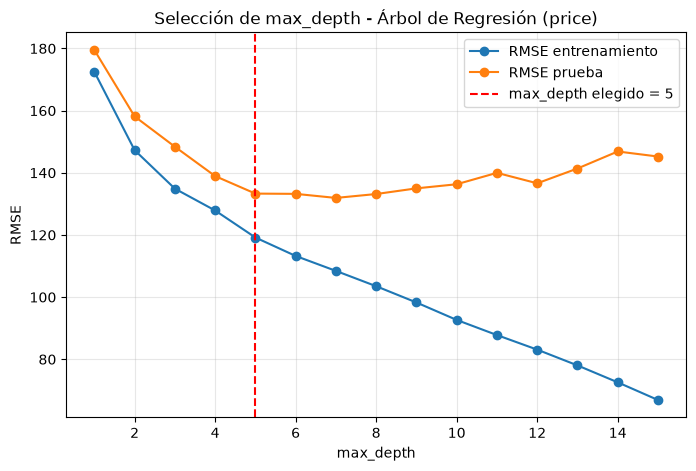

Profundidad con menor RMSE de prueba: 7 (RMSE prueba = 131.91)
Profundidad elegida:                  5 (RMSE prueba = 133.30)

max_depth=5: RMSE entrenamiento = 119.18 | RMSE prueba = 133.30 | brecha = 14.13
max_depth=7: RMSE entrenamiento = 108.44 | RMSE prueba = 131.91 | brecha = 23.48


In [29]:
profundidades = range(1, 16)
rmse_train_list, rmse_test_list = [], []

for prof in profundidades:
    modelo_temp = DecisionTreeRegressor(max_depth=prof, random_state=42)
    modelo_temp.fit(x_train, y_train)

    rmse_train = np.sqrt(mean_squared_error(y_train, modelo_temp.predict(x_train)))
    rmse_test = np.sqrt(mean_squared_error(y_test, modelo_temp.predict(x_test)))

    rmse_train_list.append(rmse_train)
    rmse_test_list.append(rmse_test)

# Profundidad elegida a partir del gráfico
PROF_REG = 5

plt.figure(figsize=(8, 5))
plt.plot(list(profundidades), rmse_train_list, marker='o', label='RMSE entrenamiento')
plt.plot(list(profundidades), rmse_test_list, marker='o', label='RMSE prueba')
plt.axvline(PROF_REG, color='red', linestyle='--', label=f'max_depth elegido = {PROF_REG}')
plt.xlabel('max_depth')
plt.ylabel('RMSE')
plt.title('Selección de max_depth - Árbol de Regresión (price)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

mejor_prof_test = list(profundidades)[int(np.argmin(rmse_test_list))]
print(f"Profundidad con menor RMSE de prueba: {mejor_prof_test} (RMSE prueba = {rmse_test_list[mejor_prof_test - 1]:.2f})")
print(f"Profundidad elegida:                  {PROF_REG} (RMSE prueba = {rmse_test_list[PROF_REG - 1]:.2f})")
print()
for p in (PROF_REG, mejor_prof_test):
    brecha = rmse_test_list[p - 1] - rmse_train_list[p - 1]
    print(f"max_depth={p}: RMSE entrenamiento = {rmse_train_list[p - 1]:.2f} | RMSE prueba = {rmse_test_list[p - 1]:.2f} | brecha = {brecha:.2f}")

Teniendo en cuenta la grafica se deja el max_depth en 5, esto puesto que aunque 7 es la profundidad con el menor RMSE la diferencia con 5 es muy pequeña y teninedo en cuenta la grafica donde desde 5 la curva de prueba basicmanete se aplana lo mejor es utilizar el 5. 

* **Configurar y entrenar el modelo**

Se crea el arbol de regresión y se ajustan los datos con .fit, adicionalmente para evitar que el arbol memorice los datos y se de un sobreajuste, se debe limitar la profundidad maxima del arbol

In [30]:
m_arbol = DecisionTreeRegressor(max_depth=PROF_REG, random_state=42)
m_arbol.fit(x_train, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"max_leaf_nodes max

* **Modelo de comparación**

Como base para comparar el modelo se hizo en este caso una regresipon lineal con las mismas variables, si el arbol no logra superar al modelo de regresipon lineal no estaria aportando valor real.

In [31]:
baseline_reg = LinearRegression()
baseline_reg.fit(x_train, y_train)
pred_baseline = baseline_reg.predict(x_test)

rmse_baseline = np.sqrt(mean_squared_error(y_test, pred_baseline))
mae_baseline = mean_absolute_error(y_test, pred_baseline)
r2_baseline = r2_score(y_test, pred_baseline)

print("Baseline (Regresión Lineal):")
print(f"  RMSE: {rmse_baseline:.2f}")
print(f"  MAE:  {mae_baseline:.2f}")
print(f"  R2:   {r2_baseline:.4f}")

Baseline (Regresión Lineal):
  RMSE: 148.84
  MAE:  87.61
  R2:   0.5194


Para tener en cuenta, el modelo baseline de regresión lineal explica el 51,9% de la variacipon del precio para el conjunto de prueba.

* **Realizar las predicciones**

Como ya esta entrenado, se le da al arbol el 20% de datos reservados para ver como calcula la variable de interes de forma independiente

In [32]:
predic_train = m_arbol.predict(x_train)
predic = m_arbol.predict(x_test)

* **Evaluar la calidad del modelo**

Se comparan la variable de interes del entrenamiento contra la variable de interes de prueba, osea las predicciones

In [34]:
rmse_train = np.sqrt(mean_squared_error(y_train, predic_train))
mae_train = mean_absolute_error(y_train, predic_train)
r2_train = r2_score(y_train, predic_train)

rmse = np.sqrt(mean_squared_error(y_test, predic))
mae = mean_absolute_error(y_test, predic)
r2 = r2_score(y_test, predic)

print(f"Árbol de Regresión (max_depth={PROF_REG})")
print(f"{'Métrica':<10}{'Entrenamiento':>15}{'Prueba':>15}")
print(f"{'RMSE':<10}{rmse_train:>15.2f}{rmse:>15.2f}")
print(f"{'MAE':<10}{mae_train:>15.2f}{mae:>15.2f}")
print(f"{'R2':<10}{r2_train:>15.4f}{r2:>15.4f}")
print()
print("Comparación en prueba contra el baseline (Regresión Lineal):")
print(f"{'Métrica':<10}{'Reg. Lineal':>15}{'Árbol':>15}")
print(f"{'RMSE':<10}{rmse_baseline:>15.2f}{rmse:>15.2f}")
print(f"{'MAE':<10}{mae_baseline:>15.2f}{mae:>15.2f}")
print(f"{'R2':<10}{r2_baseline:>15.4f}{r2:>15.4f}")

Árbol de Regresión (max_depth=5)
Métrica     Entrenamiento         Prueba
RMSE               119.18         133.30
MAE                 69.06          73.07
R2                 0.6440         0.6145

Comparación en prueba contra el baseline (Regresión Lineal):
Métrica       Reg. Lineal          Árbol
RMSE               148.84         133.30
MAE                 87.61          73.07
R2                 0.5194         0.6145


**Conclusión:**

El arbol fijando una profundidad de 5 tuvo un R2 de 0,614 en prueba mientras la refresión lineal tuvo uno de 0,519, esto significa que el arbol explica el 61% de la variación del precio contra casi un 52% del baseline, sin contar que ademas el arbol tiene un mejor RMSE. Finalmente si comparamos R2 del arbol de entrenamiento vs el de prueba son bastante parecidos, esto nos permite concluir que el modelo no esta sobreajustado.


* **Importancia de las variables**

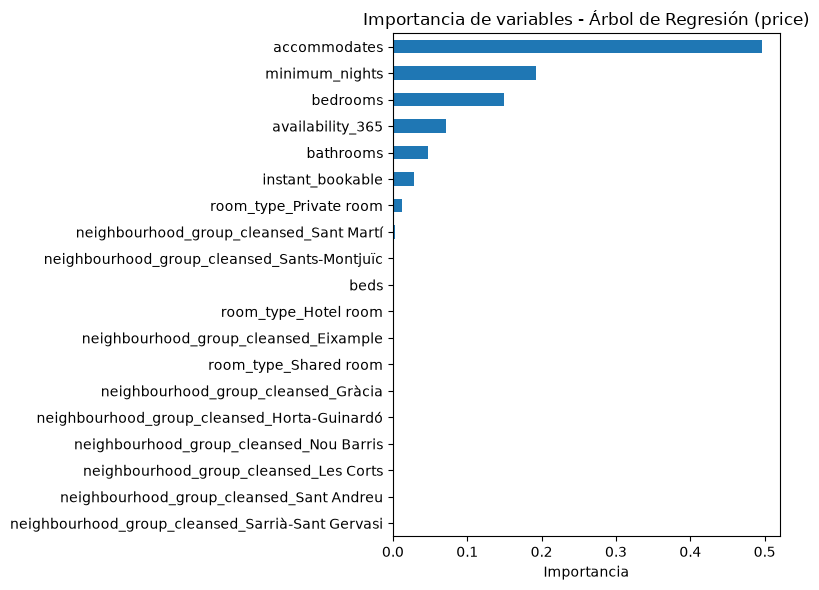

In [35]:
importancias = pd.Series(m_arbol.feature_importances_, index=x.columns).sort_values(ascending=False)

plt.figure(figsize=(8, 6))
importancias.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Importancia')
plt.title('Importancia de variables - Árbol de Regresión (price)')
plt.tight_layout()
plt.show()

**Conclusión:**

Esta gráfica muestra cuáles variables utiliza más el árbol para predecir el precio. Las barras más grandes representan las características que más influyen en sus decisiones. Si se tiene en cuenta la grafica se concluye que en nuestro caso el precio depende mas qeu todo del tamaño de el airbnb y la estadia minima que exije.


* **Exploración de hiperparametros**

En el modelo unicamente se cambio max_depth, sin embargo los arboles de regseión y clasificación tienen muchos mas hiperparametros que se pueden cambiar y controlar para regular la complejidad y evitar el sobreajuste. Entre estos parametros estan:

    * **Min_samples_split:** 

    * **Min_samples_leaf:** 







Teniendo esto en cuenta se quiso jugar un poco con estos parametros para nuestro arbol de regresión, para esto se dejo el max_depth en 5 y se cambio un hiperparametro a la vez. Adicionalmente cada parametro se evalua con validación cruzada sobre el conjunto de entrenamiento y se reporta el RMSE promedio del entrenamiento y de validación, un RMSE menos es mejor


In [36]:
cv_reg = KFold(n_splits=5, shuffle=True, random_state=42)
modelo_base_reg = DecisionTreeRegressor(max_depth=PROF_REG, random_state=42)


def explorar_hiperparametro(modelo, parametro, valores, X, y, cv, scoring,
                            metrica='RMSE', mayor_es_mejor=False):
    """Varía UN hiperparámetro (los demás quedan fijos) y evalúa con validación
    cruzada sobre el conjunto de entrenamiento. Grafica y devuelve la tabla."""
    train_sc, val_sc = validation_curve(modelo, X, y, param_name=parametro,
                                        param_range=valores, cv=cv,
                                        scoring=scoring, n_jobs=-1)
    if not mayor_es_mejor:            # sklearn devuelve los errores en negativo
        train_sc, val_sc = -train_sc, -val_sc

    etiquetas = ['None' if v is None else str(v) for v in valores]
    col_train, col_val = f'{metrica} entrenamiento', f'{metrica} validación'
    tabla = pd.DataFrame({col_train: train_sc.mean(axis=1),
                          col_val: val_sc.mean(axis=1),
                          'desv. validación': val_sc.std(axis=1)}, index=etiquetas)
    tabla.index.name = parametro

    idx = int(np.argmax(tabla[col_val])) if mayor_es_mejor else int(np.argmin(tabla[col_val]))
    pos = np.arange(len(valores))

    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(pos, tabla[col_train], marker='o', label=f'{metrica} entrenamiento (CV)')
    ax.plot(pos, tabla[col_val], marker='o', label=f'{metrica} validación (CV)')
    ax.fill_between(pos, tabla[col_val] - tabla['desv. validación'],
                    tabla[col_val] + tabla['desv. validación'], alpha=0.15)
    ax.scatter(pos[idx], tabla[col_val].iloc[idx], s=200, facecolors='none',
               edgecolors='red', linewidths=2, label='mejor validación')
    ax.set_xticks(pos)
    ax.set_xticklabels(etiquetas)
    ax.set_xlabel(parametro)
    ax.set_ylabel(metrica)
    ax.set_title(f'Efecto de {parametro}')
    ax.grid(alpha=0.3)
    ax.legend()
    plt.tight_layout()
    plt.show()

    display(tabla.round(4))
    print(f"Mejor valor de {parametro} según validación: {etiquetas[idx]}")
    return tabla

* * Min_samples_split: Es el minimo de obsetrvaciónes que debe tener un nodo para dividirse, si su numero se aumenta, el arbol se vuelve mas simple.


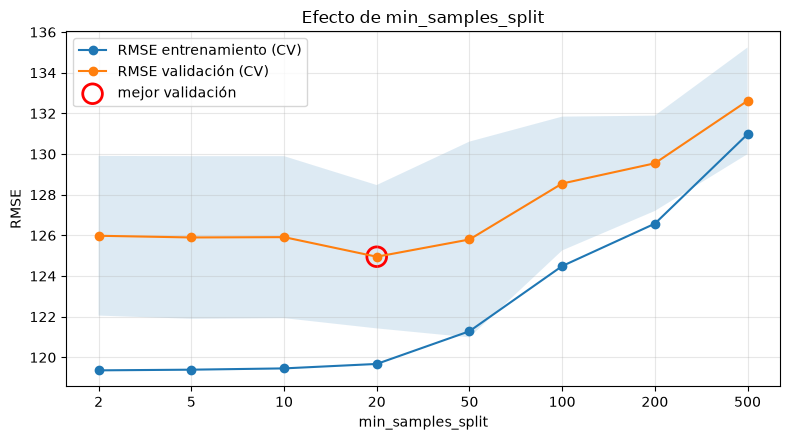

,RMSE entrenamiento,RMSE validación,desv. validación
min_samples_split,,,
2,119.3596,125.9799,3.9263
5,119.3926,125.8965,4.0006
10,119.4558,125.9131,3.9841
20,119.6748,124.9493,3.5259
50,121.2842,125.7969,4.8145
100,124.4890,128.5488,3.2916
200,126.5752,129.5449,2.3448
500,130.9767,132.6191,2.6225


Mejor valor de min_samples_split según validación: 20


In [37]:
res_split = explorar_hiperparametro(modelo_base_reg, 'min_samples_split',
                                    [2, 5, 10, 20, 50, 100, 200, 500],
                                    x_train, y_train, cv_reg, scoring='neg_root_mean_squared_error', metrica='RMSE')

Entre 20 y 50 el RMSE casi no cambia, sin embargo el mejor min_samples_split es 20 con un rmse DE 124,95. Por otra parte desde 100 el arbol genera un subajuste.

* * Min_samples_leaf: es el minimo de observaciones qeu debe tener una hoja, cuando se aumenta las hojas se vuelven mas estables (menos afectadas por el ruido)
* * min_weight_fraction_leaf: es lo mismo que el anterior pero se establece un minimo de fracción del total.

c:\Users\majos\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


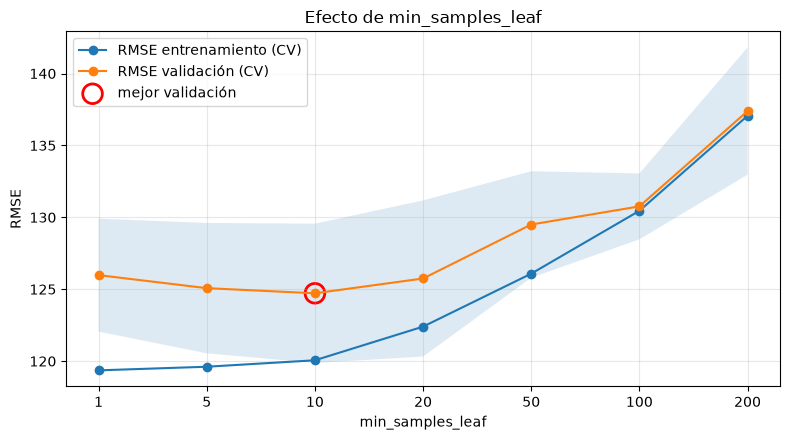

,RMSE entrenamiento,RMSE validación,desv. validación
min_samples_leaf,,,
1,119.3596,125.9799,3.9263
5,119.6112,125.0756,4.5348
10,120.0594,124.7177,4.8416
20,122.3997,125.7471,5.4291
50,126.0836,129.5011,3.7024
100,130.4530,130.7608,2.2912
200,137.0626,137.3870,4.4234


Mejor valor de min_samples_leaf según validación: 10


In [38]:
res_leaf = explorar_hiperparametro(modelo_base_reg, 'min_samples_leaf',
                                   [1, 5, 10, 20, 50, 100, 200],
                                   x_train, y_train, cv_reg, scoring='neg_root_mean_squared_error', metrica='RMSE')

En este caso el mejor valor para min_samples_leaf es 10, pocas observaciónes evita que las ojas memoricen casos especificos. 

* * Max_features: establece el numero de variables que se consideran para buscar cada división. con menos variables hay mayor aleatoriedad y menos ajuste.


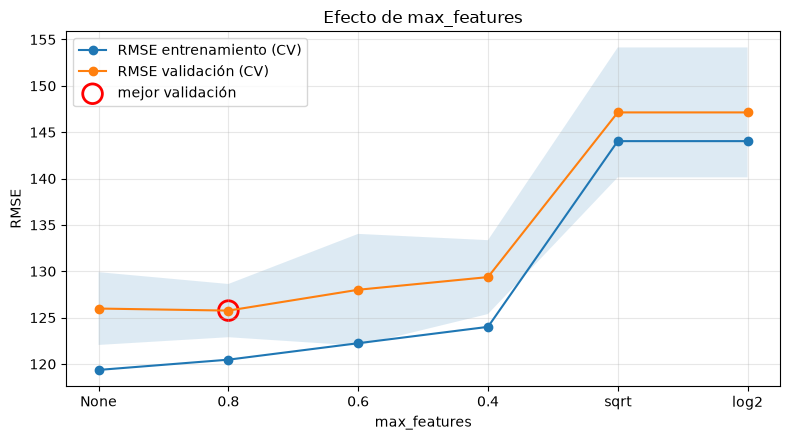

,RMSE entrenamiento,RMSE validación,desv. validación
max_features,,,
None,119.3596,125.9799,3.9263
0.8,120.4656,125.7583,2.8710
0.6,122.2416,128.0060,6.0271
0.4,124.0053,129.3720,3.9841
sqrt,144.0373,147.1347,7.0054
log2,144.0373,147.1347,7.0054


Mejor valor de max_features según validación: 0.8


In [ ]:
# None = todas las variables. Con 19 variables, 'sqrt' y 'log2' equivalen a 4.
res_maxf = explorar_hiperparametro(modelo_base_reg, 'max_features',
                                   [None, 0.8, 0.6, 0.4, 'sqrt', 'log2'],
                                   x_train, y_train, cv_reg, scoring='neg_root_mean_squared_error', metrica='RMSE')

Considerar todas las variables el el 80% de ellas da casi qeu el mismo resultado sinedo el 80% mejor, si se reducen las variables disponibles en cada división el arbol pierde la posibilidad de elegir a mejor división. Basicamente cambiar max_features solo le quita información a un solo arbol (pero es util para random forest)

* * Max_leaf_nodes: es el numero maximo de hojas, entre mas hojas el modelo adquiere mas complejidad.

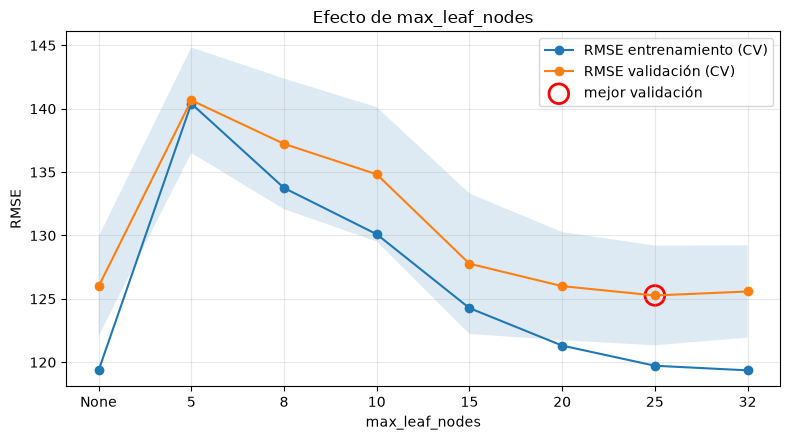

,RMSE entrenamiento,RMSE validación,desv. validación
max_leaf_nodes,,,
None,119.3596,125.9799,3.9263
5,140.4065,140.6683,4.1646
8,133.7501,137.2288,5.1511
10,130.0993,134.8277,5.2980
15,124.2714,127.7743,5.5414
20,121.3143,126.0029,4.2687
25,119.7237,125.2690,3.9325
32,119.3596,125.5810,3.6368


Mejor valor de max_leaf_nodes según validación: 25


In [40]:
res_leafnodes = explorar_hiperparametro(modelo_base_reg, 'max_leaf_nodes',
                                        [None, 5, 8, 10, 15, 20, 25, 32],
                                        x_train, y_train, cv_reg, scoring='neg_root_mean_squared_error', metrica='RMSE')

Si se limita el numero de hojas debajo de 15 se perjudica el modelo porque el arbol no alcanza a separar los distintos tipos de alojamiento. Aunque entre 20 y 32 hojas el resuntado es el mismo el menor RMSE se encuentra en 25.

* * Min_impurity_decrease: indica la reducción minima de error que debe lograr una división para poder hacerse, si lo aumentas el arbol se vuelve mas simple por lo que evita divisiones poco utiles.

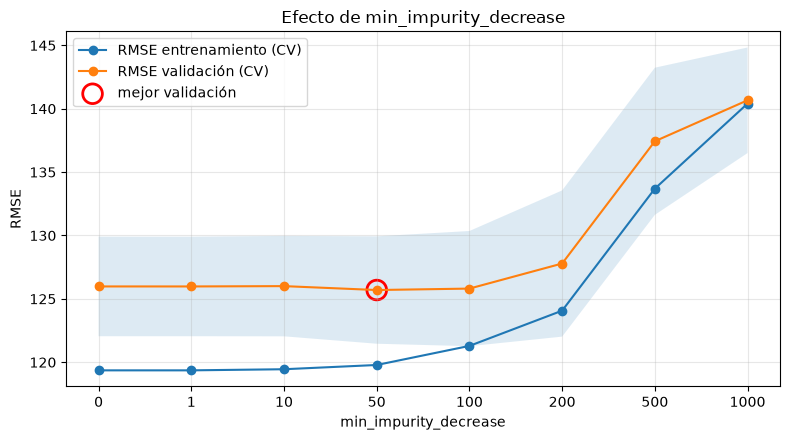

,RMSE entrenamiento,RMSE validación,desv. validación
min_impurity_decrease,,,
0,119.3596,125.9799,3.9263
1,119.3596,125.9790,3.9265
10,119.4477,126.0051,3.9616
50,119.7831,125.6967,4.2368
100,121.2887,125.8105,4.5438
200,124.0685,127.7882,5.7675
500,133.6942,137.4328,5.8045
1000,140.4065,140.6683,4.1646


Mejor valor de min_impurity_decrease según validación: 50


In [41]:
res_impurity = explorar_hiperparametro(modelo_base_reg, 'min_impurity_decrease',
                                       [0, 1, 10, 50, 100, 200, 500, 1000],
                                       x_train, y_train, cv_reg, scoring='neg_root_mean_squared_error', metrica='RMSE')

Con valores pequeños el resultado practicamente no cambia, en este caso el mejor valor para el hiperparametro es 50 porque solo se eliminan divisiones que no reducen el error, sin embargo a partir de 200 o mas se eliminan divisiones utiles por lo que el error sube. 

* * Random_satate: define el orden en que se prueban las variables, si se aumenta no mejora el modelo pero se asegura la reproducibilidad.

Cuando el arbol considera todas las variables, la semilla solo influye para desempatar divisiones igual de buenas entonces casi no cambia el resultado, pero cuando se usa max_features menor el resultado si varia porque cada semilla hace un subconjunto disnto de variables, teniendo esto en cuenta se prueban 20 semillas con ambas configuraciones

c:\Users\majos\AppData\Local\Programs\Python\Python314\Lib\site-packages\joblib\externals\loky\process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


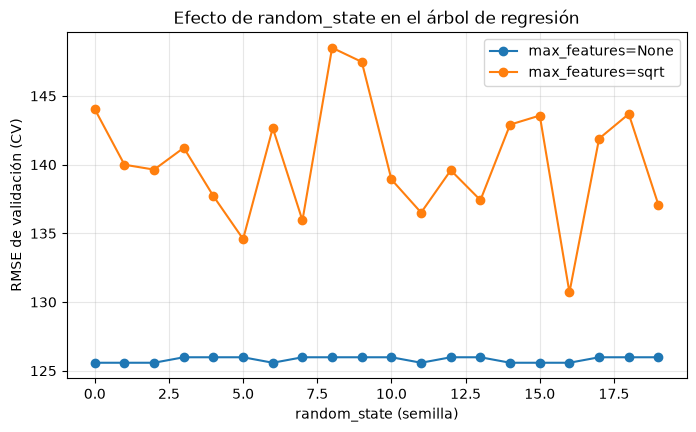

,media,desv. estándar,mínimo,máximo
max_features=None,125.82,0.195,125.581,125.980
max_features=sqrt,140.20,4.227,130.699,148.505


In [42]:
semillas = list(range(20))
resumen_seeds = {}

plt.figure(figsize=(8, 4.5))
for mf in [None, 'sqrt']:
    _, val_sc = validation_curve(DecisionTreeRegressor(max_depth=PROF_REG, max_features=mf),
                                 x_train, y_train, param_name='random_state',
                                 param_range=semillas, cv=cv_reg,
                                 scoring='neg_root_mean_squared_error', n_jobs=-1)
    rmse_seeds = -val_sc.mean(axis=1)
    plt.plot(semillas, rmse_seeds, marker='o', label=f'max_features={mf}')
    resumen_seeds[f'max_features={mf}'] = {'media': rmse_seeds.mean(), 'desv. estándar': rmse_seeds.std(),
                                          'mínimo': rmse_seeds.min(), 'máximo': rmse_seeds.max()}

plt.xlabel('random_state (semilla)')
plt.ylabel('RMSE de validación (CV)')
plt.title('Efecto de random_state en el árbol de regresión')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

display(pd.DataFrame(resumen_seeds).T.round(3))

Con los resultados se comprueba qeu con un arbol que considera todas las variables cambiar la semilla no afecta casi nada, mientras qeu si ponemos a max_features = sqrt la semilla si importa, por esto es que usualmente se fija random_state en 42, de esta manera los resultados son reproducibles.

* **Combianando los hiperparametros**

Despuesde probar el mejor para cada hiperparametro se puede hacer una combinación en el modelo de arboles con los valores que pueden ser mejores, manteniendo max_depth en 5 y random_state en 42, el resto ve valores se elige teniendo en cuenta cual es la mejor combinación

In [43]:
param_grid_reg = {
    'min_samples_split': [2, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20],
    'min_weight_fraction_leaf': [0, 0.001],
    'max_features': [None, 0.8],
    'max_leaf_nodes': [None, 20, 25],
    'min_impurity_decrease': [0, 50, 100],
}

busqueda_reg = GridSearchCV(
    DecisionTreeRegressor(max_depth=PROF_REG, random_state=42),
    param_grid_reg, cv=cv_reg,
    scoring='neg_root_mean_squared_error', n_jobs=-1
)
busqueda_reg.fit(x_train, y_train)

print("Mejores hiperparámetros:", busqueda_reg.best_params_)
print(f"Mejor RMSE de validación (CV): {-busqueda_reg.best_score_:.2f}")
print()
print("Las 5 mejores combinaciones:")
top5_reg = pd.DataFrame(busqueda_reg.cv_results_).sort_values('rank_test_score').head(5)
top5_reg = top5_reg[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']].copy()
top5_reg['mean_test_score'] = -top5_reg['mean_test_score']
top5_reg.columns = ['ranking', 'RMSE validación', 'desv.', 'hiperparámetros']
display(top5_reg.round(3))

Mejores hiperparámetros: {'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0}
Mejor RMSE de validación (CV): 124.44

Las 5 mejores combinaciones:


,ranking,RMSE validación,desv.,hiperparámetros
8,1,124.440,4.320,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0}"
152,2,124.465,4.318,"{'max_features': None, 'max_leaf_nodes': 25, 'min_impurity_decrease': 0, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0}"
176,3,124.716,4.232,"{'max_features': None, 'max_leaf_nodes': 25, 'min_impurity_decrease': 50, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0}"
32,3,124.716,4.232,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 50, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0}"
15,5,124.718,4.842,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 10, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0.001}"


Probando todas las combinaciones se obtiene que la mejor respuesta es cuando se utiliza 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 5, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0 teniendo un RMSE de 124,4, sin embargo el resto de combinaciones tienen resultados muy similares, esto nos dice que una vez fijamos la profundidad, el resto de parametros puede afinar el modelo pero no lo cambia de manera sustancial.

* **Modelo final**

In [44]:
m_arbol_final = busqueda_reg.best_estimator_

def metricas_regresion(modelo, nombre):
    p_tr, p_te = modelo.predict(x_train), modelo.predict(x_test)
    return {'Modelo': nombre,
            'RMSE prueba': np.sqrt(mean_squared_error(y_test, p_te)),
            'MAE prueba': mean_absolute_error(y_test, p_te),
            'R2 prueba': r2_score(y_test, p_te),
            'R2 entrenamiento': r2_score(y_train, p_tr)}

comparacion_reg = pd.DataFrame([
    metricas_regresion(baseline_reg, 'Regresión Lineal (baseline)'),
    metricas_regresion(m_arbol, f'Árbol (max_depth={PROF_REG})'),
    metricas_regresion(m_arbol_final, 'Árbol ajustado (GridSearchCV)'),
]).set_index('Modelo')

display(comparacion_reg.round(4))
print(f"Hojas del árbol con max_depth={PROF_REG}: {m_arbol.get_n_leaves()} | Hojas del árbol ajustado: {m_arbol_final.get_n_leaves()}")

,RMSE prueba,MAE prueba,R2 prueba,R2 entrenamiento
Modelo,,,,
Regresión Lineal (baseline),148.8371,87.6075,0.5194,0.5016
Árbol (max_depth=5),133.3036,73.0749,0.6145,0.6440
Árbol ajustado (GridSearchCV),132.2280,72.4745,0.6207,0.6429


Hojas del árbol con max_depth=5: 32 | Hojas del árbol ajustado: 31


Comparando el conjunto con hiperparametros ajustados, el modelo con solo la profundidad fija y el baseline, se obtiene que ambos modelos que usan arboles de regresión superan al besaline, adicionalmente el modelo con los hiperparametros ajustados tiene los mejores resultados aunque no por mucho, lo que nos dice lo mismo que encontramos en la conclusion anterior, por ultimo el R2 de prueba y de entrenamiento para el arbol ajustado siguen siendo similares lo que significa que no hay sobreajuste.

* **Visualizar el arbol**

In [45]:
# arbol interactivo con supertree
try:
    from supertree import SuperTree

    st_reg = SuperTree(m_arbol_final, x_train.values, y_train.values,
                       list(x.columns), 'price')
    st_reg.show_tree(start_depth=PROF_REG)
    st_reg.save_html('arbol_regresion_interactivo', start_depth=PROF_REG)
except ImportError:
    print("Falta instalar supertree: ejecuta la celda '%pip install -q dtreeviz supertree' y reinicia el kernel.")

HTML saved to arbol_regresion_interactivo.html


### Conclusiones

El árbol de regresión con max_depth=5 logró predecir el precio con un **R2 de 0.6225** en prueba, mientras la regresión lineal usada como baseline fue de 0,5194. Por otra parte con el ajuste adicional de otros hiperparametros el modelo se refino y llego a un R2 de 0,6207. El ejercicio muestra que estos modelos son fáciles de interpretar y capturan relaciones que la regresión lineal no ve, pero es importante controlar su profundidad para evitar sobreajuste y despues jugar con los hiperparametros para poder refinarlo.

### Modelo 2: Arbol de clasificación

Hasta este punto utilizamos regresión porque queríamos predecir un número: el precio. Ahora cambiamos el problema. Queremos determinar si un alojamiento corresponde a Superhost o No Superhost, por eso utilizamos clasificación.


* **Separar las variables (columnas predictoras y variable a predecir)**

In [49]:
x_cls = df_clasificacion.drop(columns=['host_is_superhost'])
y_cls = df_clasificacion['host_is_superhost'].astype(int)   # 0 = No superhost, 1 = Superhost

* **Dividir en entrenamiento y prueba**

In [50]:
x_cls_train, x_cls_test, y_cls_train, y_cls_test = train_test_split(x_cls, y_cls, test_size=0.2, random_state=42, stratify=y_cls)

print(f"Entrenamiento: {x_cls_train.shape[0]} filas | Prueba: {x_cls_test.shape[0]} filas")
print("Proporción de superhost en entrenamiento:", y_cls_train.mean().round(3))
print("Proporción de superhost en prueba:      ", y_cls_test.mean().round(3))

Entrenamiento: 14688 filas | Prueba: 3672 filas
Proporción de superhost en entrenamiento: 0.225
Proporción de superhost en prueba:       0.225


* **selección de max depth**

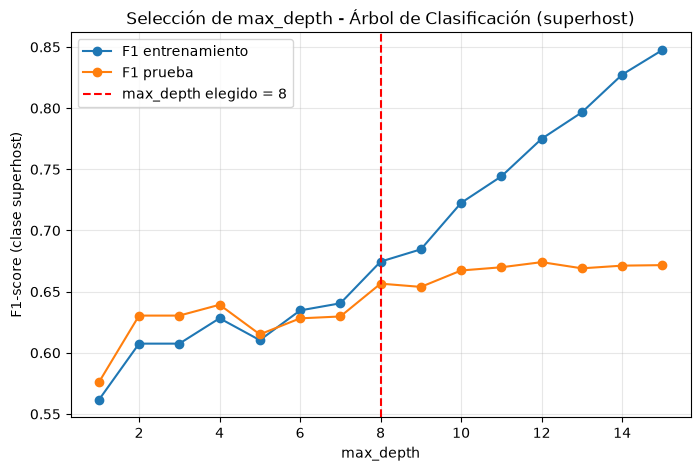

Profundidad con mejor F1 de prueba: 12 (F1 prueba = 0.6741)
Profundidad elegida:                8 (F1 prueba = 0.6566)

max_depth=8: F1 entrenamiento = 0.6746 | F1 prueba = 0.6566 | brecha = 0.0180
max_depth=12: F1 entrenamiento = 0.7750 | F1 prueba = 0.6741 | brecha = 0.1008


In [51]:
profundidades_cls = range(1, 16)
f1_train_list, f1_test_list = [], []

for prof in profundidades_cls:
    modelo_temp = DecisionTreeClassifier(max_depth=prof, random_state=42, class_weight='balanced')
    modelo_temp.fit(x_cls_train, y_cls_train)

    f1_train = f1_score(y_cls_train, modelo_temp.predict(x_cls_train))
    f1_test = f1_score(y_cls_test, modelo_temp.predict(x_cls_test))

    f1_train_list.append(f1_train)
    f1_test_list.append(f1_test)

# Profundidad elegida para el árbol de clasificación
PROF_CLS = 8

plt.figure(figsize=(8, 5))
plt.plot(list(profundidades_cls), f1_train_list, marker='o', label='F1 entrenamiento')
plt.plot(list(profundidades_cls), f1_test_list, marker='o', label='F1 prueba')
plt.axvline(PROF_CLS, color='red', linestyle='--', label=f'max_depth elegido = {PROF_CLS}')
plt.xlabel('max_depth')
plt.ylabel('F1-score (clase superhost)')
plt.title('Selección de max_depth - Árbol de Clasificación (superhost)')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

mejor_prof_cls_test = list(profundidades_cls)[int(np.argmax(f1_test_list))]
print(f"Profundidad con mejor F1 de prueba: {mejor_prof_cls_test} (F1 prueba = {f1_test_list[mejor_prof_cls_test - 1]:.4f})")
print(f"Profundidad elegida:                {PROF_CLS} (F1 prueba = {f1_test_list[PROF_CLS - 1]:.4f})")
print()
for p in (PROF_CLS, mejor_prof_cls_test):
    print(f"max_depth={p}: F1 entrenamiento = {f1_train_list[p - 1]:.4f} | F1 prueba = {f1_test_list[p - 1]:.4f} | brecha = {f1_train_list[p - 1] - f1_test_list[p - 1]:.4f}")

En este caso la profundidad maxima se fija en 8 siendo que es aquella donde la brecha entre prueba y entrenamiento todavia es baja. A paetir de 10 el arbol empieza a memorizar


* **Configurar y entrenar el modelo**

In [52]:
m_arbol_cls = DecisionTreeClassifier(max_depth=PROF_CLS, random_state=42, class_weight='balanced')
# se usa class_weight='balanced' para manejar el desbalance de clases
m_arbol_cls.fit(x_cls_train, y_cls_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are con

* **Modelo de comparación**

Para el baseline se usa una regresipin logistica que estima la probabilidad de ser superhost como una combinación lineal de variables. Para esto se ajusta el standarscaler puesto qeu el modelo de regresión logistica es sensible a la escala de variables y el clss_weitgt se deja balanceado para manejar el desvalance de clases, esto tambien se hace en el arbol

In [53]:
baseline_cls = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
)
baseline_cls.fit(x_cls_train, y_cls_train)
pred_baseline_cls = baseline_cls.predict(x_cls_test)
proba_baseline_cls = baseline_cls.predict_proba(x_cls_test)[:, 1]

print("Baseline (Regresión Logística):")
print(f"  Accuracy:  {accuracy_score(y_cls_test, pred_baseline_cls):.4f}")
print(f"  Precision: {precision_score(y_cls_test, pred_baseline_cls, zero_division=0):.4f}")
print(f"  Recall:    {recall_score(y_cls_test, pred_baseline_cls, zero_division=0):.4f}")
print(f"  F1-score:  {f1_score(y_cls_test, pred_baseline_cls, zero_division=0):.4f}")
print(f"  AUC:       {roc_auc_score(y_cls_test, proba_baseline_cls):.4f}")

Baseline (Regresión Logística):
  Accuracy:  0.7397
  Precision: 0.4554
  Recall:    0.8097
  F1-score:  0.5829
  AUC:       0.8195


El modelo de regresión logistica logra un F1 de 0,583 con un recall alto del 0,81 pero una precisipon baja de 0,46. Finalmente su AUC es de 0.8195, en este caso el arbol debe superar esta marca para qeu si aporte valor.

* **Realizar las predicciones**

In [54]:
predic_cls_train = m_arbol_cls.predict(x_cls_train)
predic_cls = m_arbol_cls.predict(x_cls_test)
proba_sh_cls = m_arbol_cls.predict_proba(x_cls_test)[:, 1]

* **Evaluar la calidad del modelo**

In [55]:
print(f"Árbol de Clasificación (max_depth={PROF_CLS}, class_weight='balanced')")
print(f"{'Métrica':<12}{'Entrenamiento':>15}{'Prueba':>15}")
print(f"{'Accuracy':<12}{accuracy_score(y_cls_train, predic_cls_train):>15.4f}{accuracy_score(y_cls_test, predic_cls):>15.4f}")
print(f"{'Precision':<12}{precision_score(y_cls_train, predic_cls_train):>15.4f}{precision_score(y_cls_test, predic_cls):>15.4f}")
print(f"{'Recall':<12}{recall_score(y_cls_train, predic_cls_train):>15.4f}{recall_score(y_cls_test, predic_cls):>15.4f}")
print(f"{'F1-score':<12}{f1_score(y_cls_train, predic_cls_train):>15.4f}{f1_score(y_cls_test, predic_cls):>15.4f}")
print()
print("Comparación en prueba contra el baseline (Regresión Logística):")
print(f"{'Métrica':<12}{'Reg. Logística':>16}{'Árbol':>10}")
print(f"{'Accuracy':<12}{accuracy_score(y_cls_test, pred_baseline_cls):>16.4f}{accuracy_score(y_cls_test, predic_cls):>10.4f}")
print(f"{'Precision':<12}{precision_score(y_cls_test, pred_baseline_cls):>16.4f}{precision_score(y_cls_test, predic_cls):>10.4f}")
print(f"{'Recall':<12}{recall_score(y_cls_test, pred_baseline_cls):>16.4f}{recall_score(y_cls_test, predic_cls):>10.4f}")
print(f"{'F1-score':<12}{f1_score(y_cls_test, pred_baseline_cls):>16.4f}{f1_score(y_cls_test, predic_cls):>10.4f}")
print(f"{'AUC':<12}{roc_auc_score(y_cls_test, proba_baseline_cls):>16.4f}{roc_auc_score(y_cls_test, proba_sh_cls):>10.4f}")
print()
print("Reporte de clasificación completo del árbol (conjunto de prueba):")
print(classification_report(y_cls_test, predic_cls, target_names=['No superhost', 'Superhost']))

Árbol de Clasificación (max_depth=8, class_weight='balanced')
Métrica       Entrenamiento         Prueba
Accuracy             0.8094         0.8026
Precision            0.5472         0.5389
Recall               0.8791         0.8400
F1-score             0.6746         0.6566

Comparación en prueba contra el baseline (Regresión Logística):
Métrica       Reg. Logística     Árbol
Accuracy              0.7397    0.8026
Precision             0.4554    0.5389
Recall                0.8097    0.8400
F1-score              0.5829    0.6566
AUC                   0.8195    0.8903

Reporte de clasificación completo del árbol (conjunto de prueba):
              precision    recall  f1-score   support

No superhost       0.94      0.79      0.86      2847
   Superhost       0.54      0.84      0.66       825

    accuracy                           0.80      3672
   macro avg       0.74      0.82      0.76      3672
weighted avg       0.85      0.80      0.82      3672



el arbol con una profundidad maxima de 8 clasifica correctamente  el 80% del total de observaciones de prueba, el racll fue del 84% 
(de todos los superhost reales el modelo interpreto 8 de cada 10), la precision fue de 54% (de los alojamientos que el modelo señalo como superhost, un poco mas de la mitad si lo eran)
Frente a los resultados de la regresión logistica, el arbol mejora todas las metricas y adicionalmente sabemos que nuestro modelo no tiene sobreajuste puesto que el F1 de entrenamiento y rpueba son bastante parecidos.

* **Evaluar la calidad del modelo:**
    * Matriz de confusión: Permite ver cuantos de las variables de interes fueron correctamente identificadas frenta a los que el modelo no detectó.

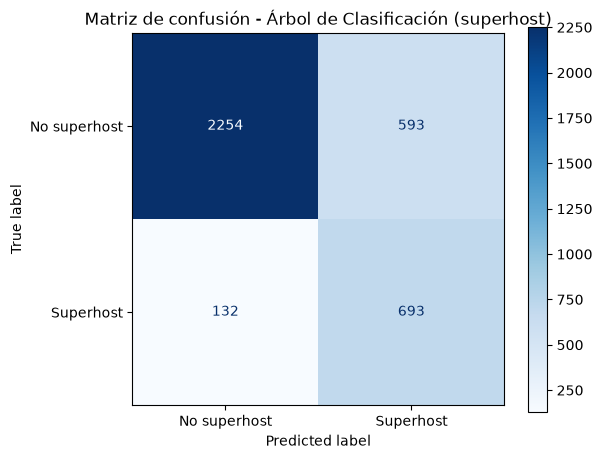

In [56]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(
    y_cls_test, predic_cls,
    display_labels=['No superhost', 'Superhost'],
    cmap='Blues', ax=ax
)
ax.set_title('Matriz de confusión - Árbol de Clasificación (superhost)')
plt.show()

**Conclusión:**

La matriz permite ver los aciertos y errores del modelo. Se observa que identifica una buena parte de los **Superhost**, aunque también existen casos que clasifica incorrectamente.


* 
    * Curva ROC y AUC:Esto complementa la matriz de confusión pues muestra el desempeño del modelo en distintos umbrales de decisión. Ademas para comparar con el baseline se incluye su cruva


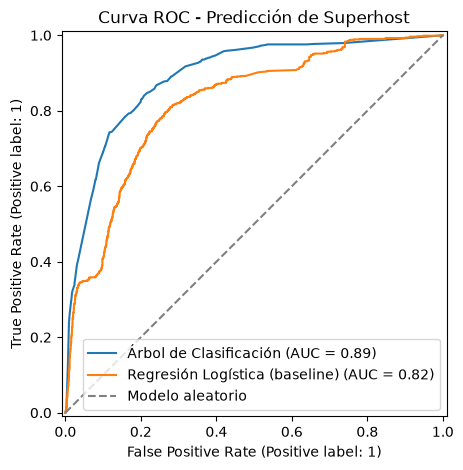

AUC árbol:0.8903
AUC regresión logística: 0.8195


In [58]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_cls_test, proba_sh_cls, ax=ax, name='Árbol de Clasificación')
RocCurveDisplay.from_predictions(y_cls_test, proba_baseline_cls, ax=ax, name='Regresión Logística (baseline)')
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Modelo aleatorio')
ax.set_title('Curva ROC - Predicción de Superhost')
ax.legend()
plt.show()

print(f"AUC árbol:{roc_auc_score(y_cls_test, proba_sh_cls):.4f}")
print(f"AUC regresión logística: {roc_auc_score(y_cls_test, proba_baseline_cls):.4f}")

**Conclusión:**

El **AUC del arbol es de 0.89**, frente al de regresión logistica de 0,81. Esto indica que el modelo de arbol tiene una buena capacidad para diferenciar entre **Superhost y No Superhost**. Cuanto más cercano a 1 sea este valor, mejor es la separación entre las clases.


* **Importancia de las variables**

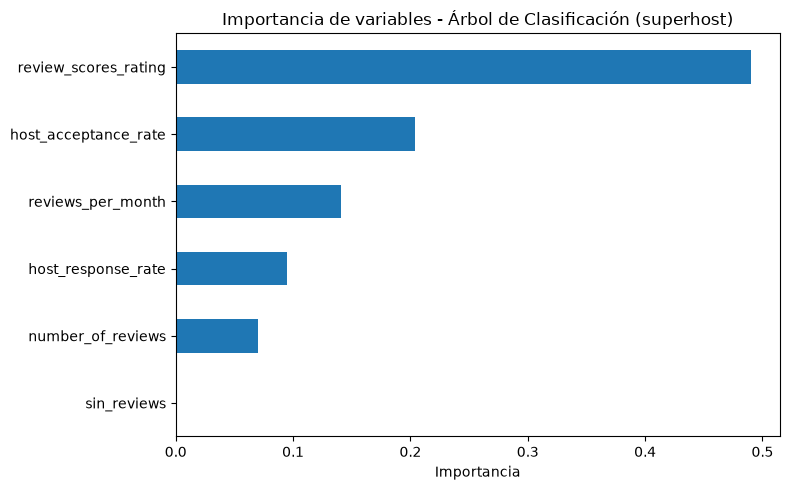

In [59]:
importancias_cls = pd.Series(
    m_arbol_cls.feature_importances_, index=x_cls.columns
).sort_values(ascending=False)

plt.figure(figsize=(8, 5))
importancias_cls.plot(kind='barh')
plt.gca().invert_yaxis()
plt.xlabel('Importancia')
plt.title('Importancia de variables - Árbol de Clasificación (superhost)')
plt.tight_layout()
plt.show()

**Conclusión:**

La gráfica muestra qué variables tienen mayor peso para decidir si un alojamiento es **Superhost**. Esto ayuda a entender qué características está utilizando el árbol para clasificar.


* **Exploración de hiperparametros:**

Igual que en el arbol de regresión se mantiene max_depth en 8 y se cambia un hiperparametro a la vez, se identifican los mejores valores y despues se realiza una combinación entre todos estos para identificar cual es la combinación que genera una mejor solución

In [60]:
cv_cls = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_base_cls = DecisionTreeClassifier(max_depth=PROF_CLS, random_state=42, class_weight='balanced')

* * Min_samples_split

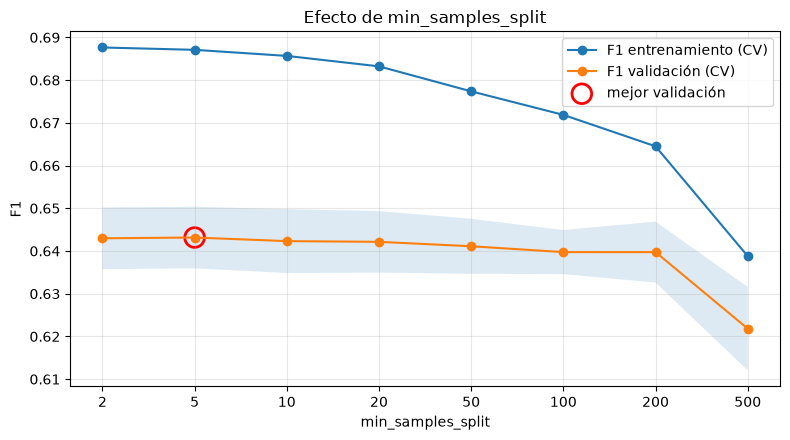

,F1 entrenamiento,F1 validación,desv. validación
min_samples_split,,,
2,0.6876,0.6430,0.0072
5,0.6871,0.6432,0.0072
10,0.6857,0.6423,0.0075
20,0.6832,0.6421,0.0072
50,0.6774,0.6411,0.0064
100,0.6719,0.6397,0.0052
200,0.6645,0.6397,0.0071
500,0.6388,0.6218,0.0098


Mejor valor de min_samples_split según validación: 5


In [61]:
res_split_cls = explorar_hiperparametro(modelo_base_cls, 'min_samples_split',
                                        [2, 5, 10, 20, 50, 100, 200, 500],
                                        x_cls_train, y_cls_train, cv_cls, scoring='f1', metrica='F1', mayor_es_mejor=True)

El f1 es basicamente plano hasta el 200 donde cae, finalmente min_samples_split casi no afecta el resultado del modelo

* * Min_sa,ples_leaf:

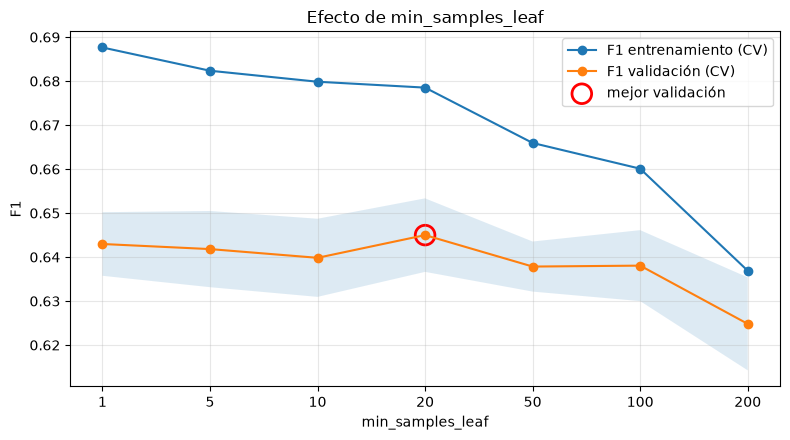

,F1 entrenamiento,F1 validación,desv. validación
min_samples_leaf,,,
1,0.6876,0.6430,0.0072
5,0.6824,0.6418,0.0087
10,0.6799,0.6398,0.0089
20,0.6785,0.6450,0.0084
50,0.6659,0.6378,0.0057
100,0.6601,0.6381,0.0081
200,0.6369,0.6248,0.0106


Mejor valor de min_samples_leaf según validación: 20


In [62]:
res_leaf_cls = explorar_hiperparametro(modelo_base_cls, 'min_samples_leaf',
                                       [1, 5, 10, 20, 50, 100, 200],
                                       x_cls_train, y_cls_train, cv_cls, scoring='f1', metrica='F1', mayor_es_mejor=True)

* * Max_features:

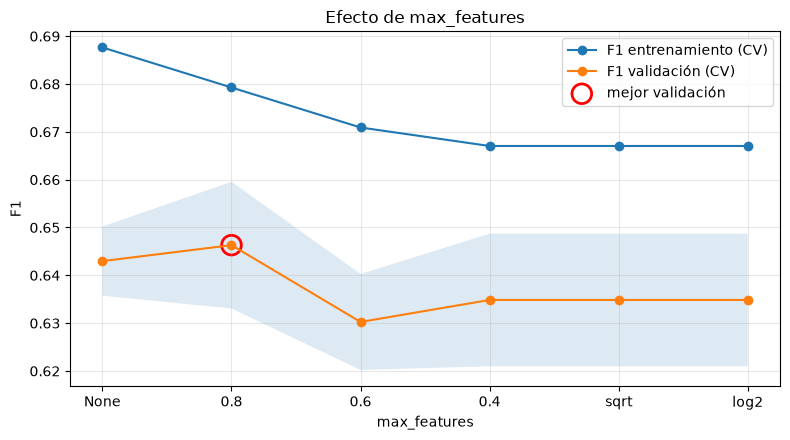

,F1 entrenamiento,F1 validación,desv. validación
max_features,,,
None,0.6876,0.6430,0.0072
0.8,0.6793,0.6463,0.0132
0.6,0.6709,0.6303,0.0100
0.4,0.6670,0.6348,0.0139
sqrt,0.6670,0.6348,0.0139
log2,0.6670,0.6348,0.0139


Mejor valor de max_features según validación: 0.8


In [63]:
# None = todas las variables. Con solo 6 variables, 'sqrt' y 'log2' equivalen a 2.
res_maxf_cls = explorar_hiperparametro(modelo_base_cls, 'max_features',
                                       [None, 0.8, 0.6, 0.4, 'sqrt', 'log2'],
                                       x_cls_train, y_cls_train, cv_cls, scoring='f1', metrica='F1', mayor_es_mejor=True)

* * Max_leaf_nodes

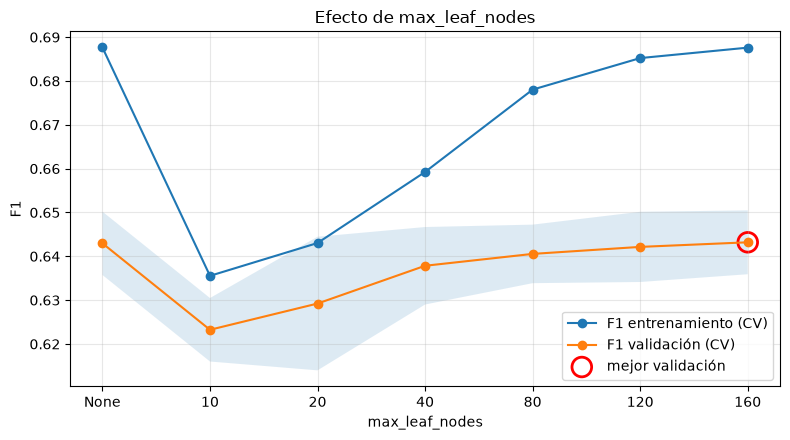

,F1 entrenamiento,F1 validación,desv. validación
max_leaf_nodes,,,
None,0.6876,0.6430,0.0072
10,0.6355,0.6232,0.0072
20,0.6430,0.6292,0.0152
40,0.6592,0.6378,0.0088
80,0.6780,0.6406,0.0067
120,0.6852,0.6421,0.0080
160,0.6876,0.6432,0.0073


Mejor valor de max_leaf_nodes según validación: 160


In [64]:
# Un árbol con max_depth=8 puede llegar a tener hasta 256 hojas.
res_leafnodes_cls = explorar_hiperparametro(modelo_base_cls, 'max_leaf_nodes',
                                            [None, 10, 20, 40, 80, 120, 160],
                                            x_cls_train, y_cls_train, cv_cls, scoring='f1', metrica='F1', mayor_es_mejor=True)

* * Min_impurity_decrease

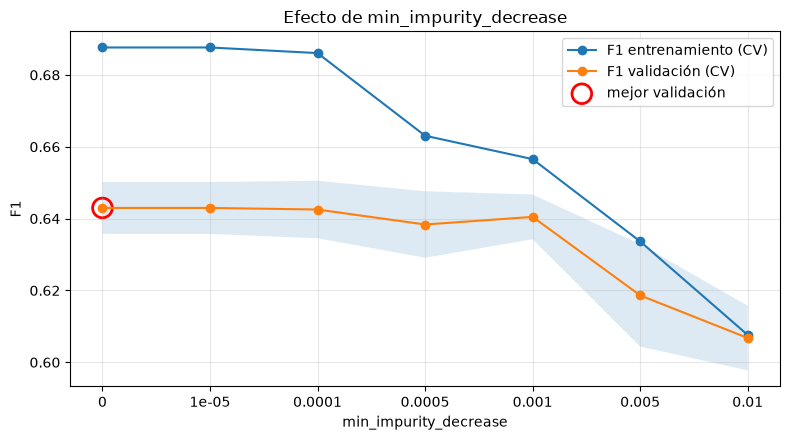

,F1 entrenamiento,F1 validación,desv. validación
min_impurity_decrease,,,
0,0.6876,0.6430,0.0072
1e-05,0.6876,0.6430,0.0072
0.0001,0.6861,0.6425,0.0080
0.0005,0.6631,0.6384,0.0093
0.001,0.6566,0.6405,0.0062
0.005,0.6336,0.6186,0.0142
0.01,0.6076,0.6068,0.0090


Mejor valor de min_impurity_decrease según validación: 0


In [65]:
res_impurity_cls = explorar_hiperparametro(modelo_base_cls, 'min_impurity_decrease',
                                           [0, 0.00001, 0.0001, 0.0005, 0.001, 0.005, 0.01],
                                           x_cls_train, y_cls_train, cv_cls, scoring='f1', metrica='F1', mayor_es_mejor=True)

* * Random_state: Aqui pasa como en la regresión con un max_features menor la semilla si importa

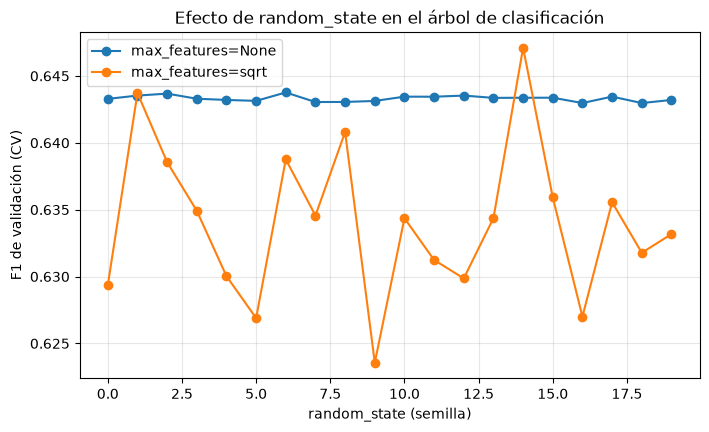

,media,desv. estándar,mínimo,máximo
max_features=None,0.6433,0.0002,0.6430,0.6438
max_features=sqrt,0.6341,0.0057,0.6236,0.6471


In [66]:
semillas = list(range(20))
resumen_seeds_cls = {}

plt.figure(figsize=(8, 4.5))
for mf in [None, 'sqrt']:
    _, val_sc = validation_curve(
        DecisionTreeClassifier(max_depth=PROF_CLS, max_features=mf, class_weight='balanced'),
        x_cls_train, y_cls_train, param_name='random_state', param_range=semillas,
        cv=cv_cls, scoring='f1', n_jobs=-1)
    f1_seeds = val_sc.mean(axis=1)
    plt.plot(semillas, f1_seeds, marker='o', label=f'max_features={mf}')
    resumen_seeds_cls[f'max_features={mf}'] = {'media': f1_seeds.mean(), 'desv. estándar': f1_seeds.std(),
                                              'mínimo': f1_seeds.min(), 'máximo': f1_seeds.max()}

plt.xlabel('random_state (semilla)')
plt.ylabel('F1 de validación (CV)')
plt.title('Efecto de random_state en el árbol de clasificación')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

display(pd.DataFrame(resumen_seeds_cls).T.round(4))

Se fija random_state en 42 para uqe los resultados sean reproducibles

* **Combinando hiperparametros**

Se deja max_depth en 8, class_weight='balanced' y random_stante=42 y se busca la mejor combinación entre los mejores valores de los distintos hiperparametros

In [67]:
param_grid_cls = {
    'min_samples_split': [2, 20, 50],
    'min_samples_leaf': [1, 10, 20, 50],
    'min_weight_fraction_leaf': [0, 0.001],
    'max_features': [None, 0.6],
    'max_leaf_nodes': [None, 80, 120],
    'min_impurity_decrease': [0, 0.0001, 0.0005],
}

busqueda_cls = GridSearchCV(
    DecisionTreeClassifier(max_depth=PROF_CLS, random_state=42, class_weight='balanced'),
    param_grid_cls, cv=cv_cls, scoring='f1', n_jobs=-1
)
busqueda_cls.fit(x_cls_train, y_cls_train)

print("Mejores hiperparámetros:", busqueda_cls.best_params_)
print(f"Mejor F1 de validación (CV): {busqueda_cls.best_score_:.4f}")
print()
print("Las 5 mejores combinaciones:")
top5_cls = pd.DataFrame(busqueda_cls.cv_results_).sort_values('rank_test_score').head(5)
top5_cls = top5_cls[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']]
top5_cls.columns = ['ranking', 'F1 validación', 'desv.', 'hiperparámetros']
display(top5_cls.round(4))

Mejores hiperparámetros: {'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0}
Mejor F1 de validación (CV): 0.6452

Las 5 mejores combinaciones:


,ranking,F1 validación,desv.,hiperparámetros
16,1,0.6452,0.0090,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0}"
17,1,0.6452,0.0090,"{'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0.001}"
161,1,0.6452,0.0090,"{'max_features': None, 'max_leaf_nodes': 120, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0.001}"
160,1,0.6452,0.0090,"{'max_features': None, 'max_leaf_nodes': 120, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0}"
159,5,0.6450,0.0084,"{'max_features': None, 'max_leaf_nodes': 120, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 20, 'min_weight_fraction_leaf': 0.001}"


La mejor combinaciín es 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0, 'min_samples_leaf': 20, 'min_samples_split': 50, 'min_weight_fraction_leaf': 0, como en el de regresión su diferencia con el F1 del modelo con unicamente profundidad fija es muy pequeña por lo tanto el modelo si se refina al ajustar otros hiperparametros pero el fundamental es la profundidad maxima

* **Modelo final**

In [68]:
m_arbol_cls_final = busqueda_cls.best_estimator_

def metricas_clasificacion(modelo, nombre):
    p_te = modelo.predict(x_cls_test)
    p_tr = modelo.predict(x_cls_train)
    return {'Modelo': nombre,
            'Accuracy': accuracy_score(y_cls_test, p_te),
            'Precision': precision_score(y_cls_test, p_te, zero_division=0),
            'Recall': recall_score(y_cls_test, p_te, zero_division=0),
            'F1 prueba': f1_score(y_cls_test, p_te, zero_division=0),
            'F1 entrenamiento': f1_score(y_cls_train, p_tr, zero_division=0),
            'AUC': roc_auc_score(y_cls_test, modelo.predict_proba(x_cls_test)[:, 1])}

comparacion_cls = pd.DataFrame([
    metricas_clasificacion(baseline_cls, 'Regresión Logística (baseline)'),
    metricas_clasificacion(m_arbol_cls, f'Árbol (max_depth={PROF_CLS})'),
    metricas_clasificacion(m_arbol_cls_final, 'Árbol ajustado (GridSearchCV)'),
]).set_index('Modelo')

display(comparacion_cls.round(4))
print(f"Hojas del árbol con max_depth={PROF_CLS}: {m_arbol_cls.get_n_leaves()} | Hojas del árbol ajustado: {m_arbol_cls_final.get_n_leaves()}")

,Accuracy,Precision,Recall,F1 prueba,F1 entrenamiento,AUC
Modelo,,,,,,
Regresión Logística (baseline),0.7397,0.4554,0.8097,0.5829,0.5759,0.8195
Árbol (max_depth=8),0.8026,0.5389,0.8400,0.6566,0.6746,0.8903
Árbol ajustado (GridSearchCV),0.8028,0.5394,0.8376,0.6562,0.6655,0.8958


Hojas del árbol con max_depth=8: 159 | Hojas del árbol ajustado: 134


Si se comparan los tres modelos realizados, los que son arboles superan la regresión logistica, adicionalmente el que tienen hiperparametros ajustados es mejor, pues esta mas refinado pero no tiene mucha diferencia con el que solo fija la profundidad, adicionalmente al comprar los F1 de prueba y entrenamiento se obtiene que el modelo de arbol ajustado no se sobreajusta

* **Visualizar el arbol**

In [69]:
try:
    from supertree import SuperTree

    st_cls = SuperTree(m_arbol_cls_final, x_cls_train.values, y_cls_train.values,
                       list(x_cls.columns), ['No superhost', 'Superhost'])
    st_cls.show_tree(start_depth=3)
    st_cls.save_html('arbol_clasificacion_interactivo', start_depth=3)
except ImportError:
    print("Falta instalar supertree: ejecuta la celda '%pip install -q dtreeviz supertree' y reinicia el kernel.")

HTML saved to arbol_clasificacion_interactivo.html


libreria que abre hojas

### Conclusión

En conclusión, con este ejercicio vimos que un árbol de decisión puede utilizarse para resolver dos tipos de problemas. Primero usamos regresión para predecir el precio de los alojamientos, con max_depth =5 logramos explicar aproximadamente el 62 % de la variación del precio en los datos de prueba. Después usamos clasificación para determinar si un alojamiento era Superhost o No Superhost, con max_depth=8 el arbol logro identificar aproximadamente 84 de cada 100 Superhost reales.

Finalmente en ambos casos, se establecio que el parametro fundamental por fijar es la profundidad maxima, despues de fijar este, el resto de parametros se puede sijar para refinar
